# Supervised Machine Learning with Scikit-Learn

This notebook provides complete, hands-on implementations and evaluations of core **Supervised Learning** algorithms using built-in **scikit-learn** datasets:

1. **Linear Regression** (Regression) — *Diabetes Dataset*
   - 1.1 Simple Linear Regression (Single Feature)
   - 1.2 Multiple Linear Regression (All Features)
   - 1.3 Polynomial Regression (Non-Linear Curve Fitting)
2. **Logistic Regression** (Binary Classification) — *Breast Cancer Wisconsin Dataset*
3. **Decision Tree Classifier** (Non-Linear Classification) — *Iris Dataset*
   - 3.1 Decision Tree with Gini Impurity
   - 3.2 Decision Tree with Entropy (Information Gain)
4. **Naïve Bayes Classifier** (Probabilistic Classification) — *Wine Dataset*
   - 4.1 Gaussian Naïve Bayes (Continuous Features)
   - 4.2 Multinomial Naïve Bayes (Frequency Counts)
   - 4.3 Bernoulli Naïve Bayes (Binary Features)
5. **Comparative Summary & Algorithm Selection Guide**

---

### Pedagogical Template (8-Step Architecture):
To serve as an optimal teaching and revision reference for students, every algorithm section is structured using the uniform 8-step workflow:
1. **Importing** — Libraries, model estimators, and metric functions.
2. **Loading Dataset** — Dataset loading, shape inspection, feature/target exploration.
3. **Split** — Train-test split, stratified sampling, and feature scaling.
4. **Train** — Model initialization and hyperparameter configuration.
5. **Fit** — Fitting the estimator on training data (`.fit()`).
6. **Predict** — Generating test predictions (`.predict()` and `.predict_proba()`).
7. **Evaluation** — Performance metrics (`accuracy_score`, `classification_report`, `confusion_matrix`, $R^2$, `MSE`).
8. **Visualization** — Decision boundaries, regression lines, confusion matrices, and tree plots.


---
# 1. Linear Regression

Linear Regression models the relationship between a continuous target variable $y$ and one or more predictor features $X$:
$$y = \beta_0 + \beta_1 X_1 + \dots + \beta_p X_p + \epsilon$$

Where:
- $\beta_0$: Intercept (value of $y$ when all $X = 0$).
- $\beta_1, \dots, \beta_p$: Coefficients (rate of change in $y$ per unit change in $X$).
- $\epsilon$: Error / residual term.


## 1.1 Simple Linear Regression (Single Feature)
Predicting diabetes disease progression using only Body Mass Index (`bmi`) to allow intuitive 2D line visualization.

> 🍋 **Layman's Analogy ("Explain Like I'm 5"):**
> Imagine you are taking a taxi. There is a flat base fee just for sitting in the car ($3, the **intercept**), and for every kilometer driven, the meter adds $2 (the **slope**). Simple Linear Regression draws the single fairest straight line through all your past taxi receipts so you can predict the cost of any future ride!


### Step 1: Importing

> 💡 *Beginner Tip:* Think of this step as grabbing your tool kit. We import only the exact tools needed for this recipe so our code stays clean and fast.
**Key Functions Explained:**
- `LinearRegression`: Ordinary Least Squares (OLS) estimator that minimizes the Residual Sum of Squares (RSS).
- `load_diabetes`: Built-in regression dataset from scikit-learn.
- `train_test_split`: Utility to partition data into training and testing subsets.
- `mean_squared_error`, `mean_absolute_error`, `r2_score`: Standard regression performance metrics.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

### Step 2: Loading Dataset

> 💡 *Beginner Tip:* Always look at your data first! Inspecting rows, columns, and feature names ensures there are no surprises or corrupted values.
**What this step does:**
We load the Diabetes dataset into a pandas DataFrame. The dataset consists of 442 diabetes patients with 10 physiological variables and a quantitative measure of disease progression one year after baseline.

[`Diabetes Dataset`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html)

In [2]:
diabetes = load_diabetes(as_frame=True)
df_diabetes = diabetes.frame

print(f"Dataset Shape: {df_diabetes.shape} (442 samples, 10 features + target)")
print("Features:", list(diabetes.feature_names))
display(df_diabetes[['bmi', 'target']].head())


Dataset Shape: (442, 11) (442 samples, 10 features + target)
Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


,bmi,target
0,0.061696,151.0
1,-0.051474,75.0
2,0.044451,141.0
3,-0.011595,206.0
4,-0.036385,135.0


### Step 3: Split

> 💡 *Beginner Tip:* Never test a student on the exact same exam questions you used for homework! We lock away 20% of the data to test fairly later.
**Key Parameters Explained:**
- `test_size=0.2`: Allocates 20% of data (89 samples) for testing and 80% (353 samples) for training.
- `random_state=42`: Sets random seed for reproducible train/test splits.


In [3]:
# 3. Train/Test Split
X_single = df_diabetes[['bmi']]
y_diabetes = df_diabetes['target']

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_single, y_diabetes, test_size=0.2, random_state=42
)

print(f"Training samples: {len(X_train_s)} | Testing samples: {len(X_test_s)}")


Training samples: 353 | Testing samples: 89


### Step 4: Train

> 💡 *Beginner Tip:* This is where we choose the model and set its knobs (hyperparameters), like setting an oven to 350°F before putting the food in.
**What this step does:**
Instantiate the `LinearRegression` model.
- `fit_intercept=True`: Calculates the bias/intercept term $\beta_0$.


In [4]:
# 4. Train: Model Initialization
lr_single = LinearRegression(fit_intercept=True)
print("Model initialized:", lr_single)


Model initialized: LinearRegression()


### Step 5: Fit

> 💡 *Beginner Tip:* This is the actual learning moment! The computer studies the examples and figures out the mathematical patterns.
**What this step does:**
Calls `.fit(X_train, y_train)` to solve the normal equations and calculate optimal weights $\beta = (X^T X)^{-1} X^T y$.


In [5]:
# 5. Fit: Model Training
lr_single.fit(X_train_s, y_train_s)

print(f"Learned Intercept (beta_0): {lr_single.intercept_:.2f}")
print(f"Learned Slope (beta_1):     {lr_single.coef_[0]:.2f}")


Learned Intercept (beta_0): 152.00
Learned Slope (beta_1):     998.58


### Step 6: Predict

> 💡 *Beginner Tip:* Now comes exam time! We feed the test questions to our model and let it make its best guesses.
**What this step does:**
Applies the learned equation $\hat{y} = \beta_0 + \beta_1 X$ onto the unseen test set `X_test_s`.


In [6]:
# 6. Predict: Model Inference
y_pred_s = lr_single.predict(X_test_s)
print(f"First 5 Predictions: {y_pred_s[:5].round(1)}")
print(f"First 5 Actuals:     {y_test_s.iloc[:5].values}")


First 5 Predictions: [145.8 188.9 148.  203.9 131.8]
First 5 Actuals:     [219.  70. 202. 230. 111.]


### Step 7: Evaluation

> 💡 *Beginner Tip:* How well did the model do? We compare its guesses with the true answer sheet and calculate report card grades (Accuracy, F1, MSE).
**Evaluation Metrics Explained:**
- **MAE (Mean Absolute Error):** $\frac{1}{n}\sum |y_i - \hat{y}_i|$ — Average absolute error in original units.
- **MSE (Mean Squared Error):** $\frac{1}{n}\sum (y_i - \hat{y}_i)^2$ — Penalizes large deviations heavily.
- **RMSE (Root Mean Squared Error):** $\sqrt{\text{MSE}}$ — Error in the same units as the target.
- **$R^2$ Score (Coefficient of Determination):** $1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$ — Proportion of target variance explained by the model (1.0 is perfect).


In [7]:
# 7. Evaluation
mae_s = mean_absolute_error(y_test_s, y_pred_s)
mse_s = mean_squared_error(y_test_s, y_pred_s)
rmse_s = np.sqrt(mse_s)
r2_s = r2_score(y_test_s, y_pred_s)

print("=" * 60)
print("SIMPLE LINEAR REGRESSION EVALUATION METRICS")
print("=" * 60)
print(f"Mean Absolute Error (MAE):     {mae_s:.2f}")
print(f"Mean Squared Error (MSE):      {mse_s:.2f}")
print(f"Root Mean Squared Error (RMSE):{rmse_s:.2f}")
print(f"R² Score (Variance Explained): {r2_s:.4f}")
print("=" * 60)


SIMPLE LINEAR REGRESSION EVALUATION METRICS
Mean Absolute Error (MAE):     52.26
Mean Squared Error (MSE):      4061.83
Root Mean Squared Error (RMSE):63.73
R² Score (Variance Explained): 0.2334


### Step 8: Visualization

> 💡 *Beginner Tip:* A picture is worth a thousand numbers! Plots help us and our stakeholders see exactly where the model succeeded and where it struggled.
**What this plot shows:**
Scatter plot of training and test observations overlaid with the fitted regression line $\hat{y} = \beta_0 + \beta_1 X$.


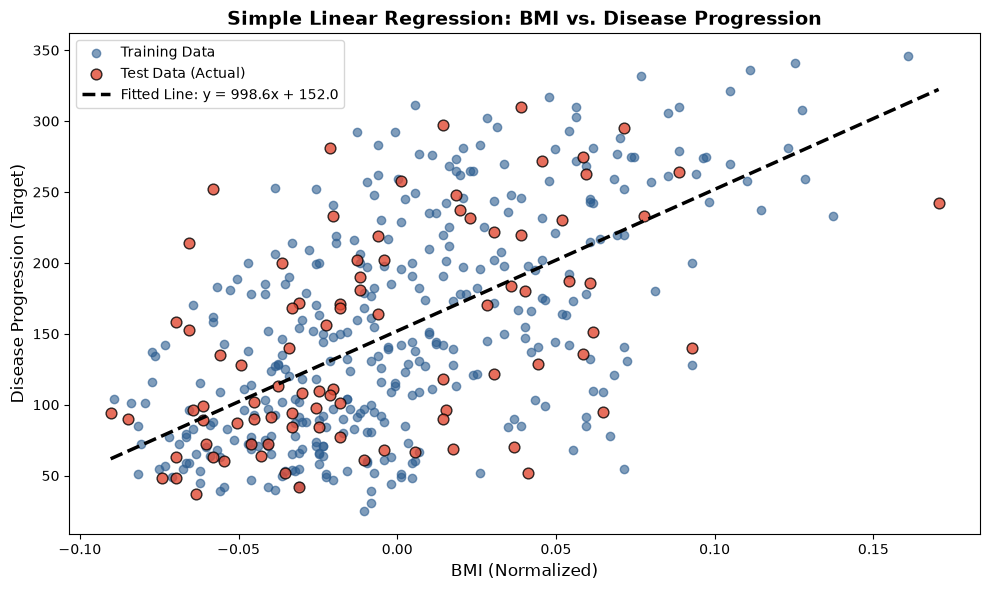

In [8]:
# 8. Visualization: Regression Line on Test & Training Data
plt.figure(figsize=(10, 6))

plt.scatter(X_train_s, y_train_s, color="#2b5c8f", alpha=0.6, label="Training Data")
plt.scatter(X_test_s, y_test_s, color="#e24a33", alpha=0.8, edgecolors='k', s=60, label="Test Data (Actual)")

# Generate line coordinates
bmi_range = np.linspace(float(X_single['bmi'].min()), float(X_single['bmi'].max()), 200).reshape(-1, 1)
y_line = lr_single.predict(pd.DataFrame(bmi_range, columns=['bmi']))

plt.plot(bmi_range, y_line, color="black", linewidth=2.5, linestyle="--",
         label=f"Fitted Line: y = {lr_single.coef_[0]:.1f}x + {lr_single.intercept_:.1f}")

plt.title("Simple Linear Regression: BMI vs. Disease Progression", fontsize=14, fontweight="bold")
plt.xlabel("BMI (Normalized)", fontsize=12)
plt.ylabel("Disease Progression (Target)", fontsize=12)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


---
## 1.2 Multiple Linear Regression (All 10 Features)
Using all available features to model complex multivariable relationships.

> 🍋 **Layman's Analogy ("Explain Like I'm 5"):**
> Now imagine your taxi fare depends on multiple things at once: kilometers driven + minutes stuck in red lights + number of heavy suitcases. Multiple Linear Regression gives each factor its own fair weight so you can predict the total bill using all the clues combined!


### Step 1: Importing

> 💡 *Beginner Tip:* Think of this step as grabbing your tool kit. We import only the exact tools needed for this recipe so our code stays clean and fast.
Imports for Multiple Linear Regression.


In [9]:
# 1. Importing libraries for Multiple Linear Regression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score



### Step 2: Loading Dataset

> 💡 *Beginner Tip:* Always look at your data first! Inspecting rows, columns, and feature names ensures there are no surprises or corrupted values.
Separating the feature matrix $X$ (10 features) from the target vector $y$.

[`Diabetes Dataset`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html)


In [10]:
# 2. Loading Dataset
diabetes_m = load_diabetes(as_frame=True)
X_multi = diabetes_m.data
y_multi = diabetes_m.target

print(f"Features ({X_multi.shape[1]}): {list(X_multi.columns)}")
display(X_multi.head(3))


Features (10): ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930


### Step 3: Split

> 💡 *Beginner Tip:* Never test a student on the exact same exam questions you used for homework! We lock away 20% of the data to test fairly later.
Splitting all 10 features into 80% train and 20% test partitions.


In [11]:
# 3. Train/Test Split
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi, y_multi, test_size=0.2, random_state=42
)

print(f"Training shape: {X_train_m.shape} | Testing shape: {X_test_m.shape}")


Training shape: (353, 10) | Testing shape: (89, 10)


### Step 4: Train

> 💡 *Beginner Tip:* This is where we choose the model and set its knobs (hyperparameters), like setting an oven to 350°F before putting the food in.
Initializing the multivariable Linear Regression model.


In [12]:
# 4. Train: Model Initialization
lr_multi = LinearRegression()
print("Multiple Linear Regression model initialized.")


Multiple Linear Regression model initialized.


### Step 5: Fit

> 💡 *Beginner Tip:* This is the actual learning moment! The computer studies the examples and figures out the mathematical patterns.
Fitting weights across all 10 dimensions simultaneously.


In [13]:
# 5. Fit: Model Training
lr_multi.fit(X_train_m, y_train_m)
print(f"Trained Intercept: {lr_multi.intercept_:.2f}")
print("Number of coefficients learned:", len(lr_multi.coef_))


Trained Intercept: 151.35
Number of coefficients learned: 10


### Step 6: Predict

> 💡 *Beginner Tip:* Now comes exam time! We feed the test questions to our model and let it make its best guesses.
Generating predictions for the test partition.


In [14]:
# 6. Predict: Model Inference
y_pred_m = lr_multi.predict(X_test_m)
print(f"Predictions calculated for {len(y_pred_m)} test samples.")


Predictions calculated for 89 test samples.


### Step 7: Evaluation

> 💡 *Beginner Tip:* How well did the model do? We compare its guesses with the true answer sheet and calculate report card grades (Accuracy, F1, MSE).
Evaluating Multiple Linear Regression metrics ($R^2$ improvement over Simple Regression).


In [15]:
# 7. Evaluation
mae_m = mean_absolute_error(y_test_m, y_pred_m)
mse_m = mean_squared_error(y_test_m, y_pred_m)
rmse_m = np.sqrt(mse_m)
r2_m = r2_score(y_test_m, y_pred_m)

print("=" * 60)
print("MULTIPLE LINEAR REGRESSION PERFORMANCE")
print("=" * 60)
print(f"Mean Absolute Error (MAE):     {mae_m:.2f}")
print(f"Mean Squared Error (MSE):      {mse_m:.2f}")
print(f"Root Mean Squared Error (RMSE):{rmse_m:.2f}")
print(f"R² Score (Variance Explained): {r2_m:.4f} (Simple LR was {r2_s:.4f})")
print("=" * 60)


MULTIPLE LINEAR REGRESSION PERFORMANCE
Mean Absolute Error (MAE):     42.79
Mean Squared Error (MSE):      2900.19
Root Mean Squared Error (RMSE):53.85
R² Score (Variance Explained): 0.4526 (Simple LR was 0.2334)


### Step 8: Visualization

> 💡 *Beginner Tip:* A picture is worth a thousand numbers! Plots help us and our stakeholders see exactly where the model succeeded and where it struggled.
**Visualizations:**
1. **Actual vs. Predicted Plot:** Evaluates alignment against the ideal identity line ($y = x$).
2. **Residual Plot:** Checks for homoscedasticity (constant variance of residuals around zero).
3. **Feature Importance (Coefficients):** Bar chart indicating positive/negative weights.


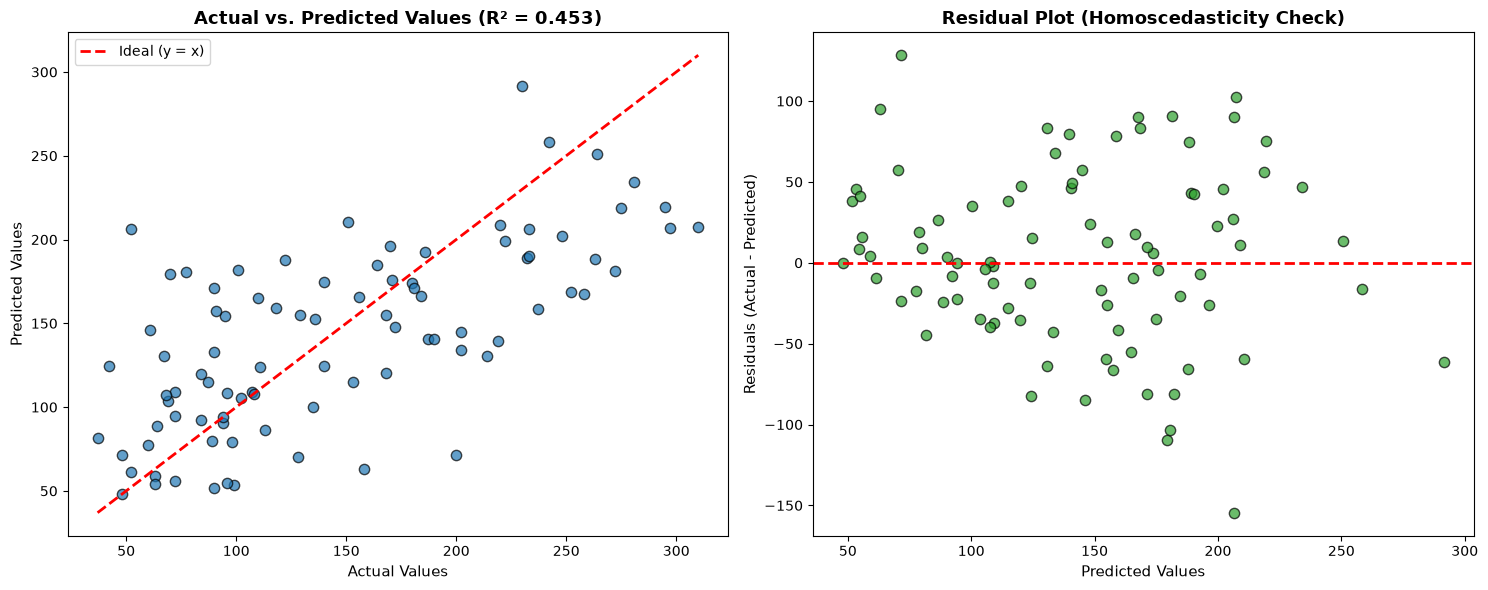

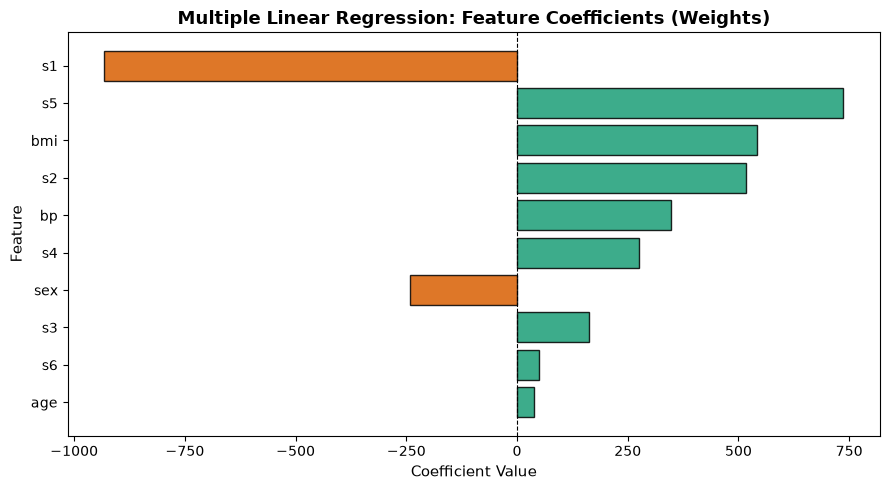

In [16]:
# 8. Visualization: Actual vs. Predicted & Residual Plot
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Actual vs Predicted
axes[0].scatter(y_test_m, y_pred_m, color="#1f77b4", alpha=0.7, edgecolors='k', s=55)
min_val = min(y_test_m.min(), y_pred_m.min())
max_val = max(y_test_m.max(), y_pred_m.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label="Ideal (y = x)")
axes[0].set_title(f"Actual vs. Predicted Values (R² = {r2_m:.3f})", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Actual Values", fontsize=11)
axes[0].set_ylabel("Predicted Values", fontsize=11)
axes[0].legend()

# Plot 2: Residual Plot
residuals = y_test_m - y_pred_m
axes[1].scatter(y_pred_m, residuals, color="#2ca02c", alpha=0.7, edgecolors='k', s=55)
axes[1].axhline(0, color='red', linestyle='--', linewidth=2)
axes[1].set_title("Residual Plot (Homoscedasticity Check)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Predicted Values", fontsize=11)
axes[1].set_ylabel("Residuals (Actual - Predicted)", fontsize=11)

plt.tight_layout()
plt.show()

# Plot 3: Feature Coefficients
coef_df = pd.DataFrame({
    'Feature': X_multi.columns,
    'Coefficient': lr_multi.coef_
}).sort_values(by='Coefficient', key=abs, ascending=True)

plt.figure(figsize=(9, 5))
colors = ['#d95f02' if c < 0 else '#1b9e77' for c in coef_df['Coefficient']]
plt.barh(coef_df['Feature'], coef_df['Coefficient'], color=colors, edgecolor='black', alpha=0.85)
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
plt.title("Multiple Linear Regression: Feature Coefficients (Weights)", fontsize=13, fontweight="bold")
plt.xlabel("Coefficient Value", fontsize=11)
plt.ylabel("Feature", fontsize=11)
plt.tight_layout()
plt.show()


---
## 1.3 Polynomial Regression (Non-Linear Curve Fitting)
Extends linear regression by synthesizing polynomial powers $X^2, X^3, \dots$ to fit non-linear curved relationships while retaining linear optimization.

> 🍋 **Layman's Analogy ("Explain Like I'm 5"):**
> When you shoot a basketball, it travels in a curved arc, not a rigid straight line! If you force a straight wooden ruler through the points, you will miss almost every shot. Polynomial regression bends the ruler into a smooth curve so it catches the arc of the ball perfectly.


### Step 1: Importing

> 💡 *Beginner Tip:* Think of this step as grabbing your tool kit. We import only the exact tools needed for this recipe so our code stays clean and fast.
**Key Function:** `PolynomialFeatures(degree=d)` generates interaction terms and powers up to degree $d$.


In [17]:
# 1. Importing libraries for Polynomial Regression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score



### Step 2: Loading Dataset

> 💡 *Beginner Tip:* Always look at your data first! Inspecting rows, columns, and feature names ensures there are no surprises or corrupted values.
Selecting single feature `bmi` to showcase the non-linear polynomial curve.

[`Diabetes Dataset`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html)


In [18]:
# 2. Loading Dataset
diabetes_p = load_diabetes(as_frame=True)
X_poly_raw = diabetes_p.frame[['bmi']]
y_poly_raw = diabetes_p.frame['target']
display(X_poly_raw.head(3))


,bmi
0,0.061696
1,-0.051474
2,0.044451


### Step 3: Split & Feature Transformation

> 💡 *Beginner Tip:* Never test a student on the exact same exam questions you used for homework! We lock away 20% of the data to test fairly later.
**Key Process:**
1. Split data into train and test sets.
2. Transform input feature $X$ into polynomial space $[X, X^2]$ using `PolynomialFeatures(degree=2, include_bias=False)`.


In [19]:
# 3. Train/Test Split & Polynomial Transformation
X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X_poly_raw, y_poly_raw, test_size=0.2, random_state=42
)

poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train_p)
X_test_poly = poly.transform(X_test_p)

print(f"Original feature shape:    {X_train_p.shape}")
print(f"Polynomial feature shape:  {X_train_poly.shape} (includes x and x^2)")


Original feature shape:    (353, 1)
Polynomial feature shape:  (353, 2) (includes x and x^2)


### Step 4: Train

> 💡 *Beginner Tip:* This is where we choose the model and set its knobs (hyperparameters), like setting an oven to 350°F before putting the food in.
Initializing linear model for polynomial fitting.


In [20]:
# 4. Train: Model Initialization
poly_reg = LinearRegression()
print("Polynomial model initialized:", poly_reg)


Polynomial model initialized: LinearRegression()


### Step 5: Fit

> 💡 *Beginner Tip:* This is the actual learning moment! The computer studies the examples and figures out the mathematical patterns.
Fitting model on the transformed polynomial design matrix.


In [21]:
# 5. Fit: Model Training
poly_reg.fit(X_train_poly, y_train_p)
print(f"Intercept: {poly_reg.intercept_:.2f}")
print("Polynomial Coefficients [x, x^2]:", poly_reg.coef_.round(2))


Intercept: 150.34
Polynomial Coefficients [x, x^2]: [975.4 763.2]


### Step 6: Predict

> 💡 *Beginner Tip:* Now comes exam time! We feed the test questions to our model and let it make its best guesses.
Generating predictions on the polynomial test features.


In [22]:
# 6. Predict: Model Inference
y_pred_poly = poly_reg.predict(X_test_poly)
print(f"Predictions generated for {len(y_pred_poly)} test samples.")


Predictions generated for 89 test samples.


### Step 7: Evaluation

> 💡 *Beginner Tip:* How well did the model do? We compare its guesses with the true answer sheet and calculate report card grades (Accuracy, F1, MSE).
Evaluating Polynomial Regression metrics.


In [23]:
# 7. Evaluation
mae_poly = mean_absolute_error(y_test_p, y_pred_poly)
mse_poly = mean_squared_error(y_test_p, y_pred_poly)
r2_poly = r2_score(y_test_p, y_pred_poly)

print("=" * 60)
print("POLYNOMIAL REGRESSION (DEGREE 2) PERFORMANCE")
print("=" * 60)
print(f"Mean Absolute Error (MAE):     {mae_poly:.2f}")
print(f"Root Mean Squared Error (RMSE):{np.sqrt(mse_poly):.2f}")
print(f"R² Score:                      {r2_poly:.4f}")
print("=" * 60)


POLYNOMIAL REGRESSION (DEGREE 2) PERFORMANCE
Mean Absolute Error (MAE):     52.38
Root Mean Squared Error (RMSE):63.91
R² Score:                      0.2290


### Step 8: Visualization

> 💡 *Beginner Tip:* A picture is worth a thousand numbers! Plots help us and our stakeholders see exactly where the model succeeded and where it struggled.
Plotting the non-linear fitted polynomial curve against scatter data.


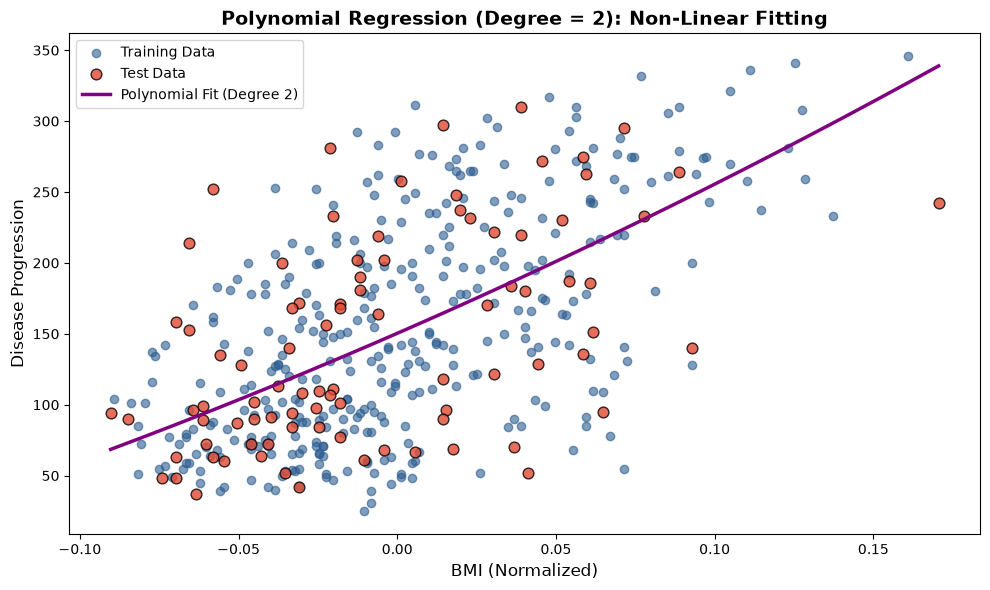

In [24]:
# 8. Visualization: Polynomial Curve vs. Data Points
plt.figure(figsize=(10, 6))

plt.scatter(X_train_p, y_train_p, color="#2b5c8f", alpha=0.6, label="Training Data")
plt.scatter(X_test_p, y_test_p, color="#e24a33", alpha=0.8, edgecolors='k', s=60, label="Test Data")

# Generate smooth curved points
x_grid = np.linspace(float(X_poly_raw['bmi'].min()), float(X_poly_raw['bmi'].max()), 200).reshape(-1, 1)
x_grid_poly = poly.transform(pd.DataFrame(x_grid, columns=['bmi']))
y_grid_pred = poly_reg.predict(x_grid_poly)

plt.plot(x_grid, y_grid_pred, color="purple", linewidth=2.5, label="Polynomial Fit (Degree 2)")
plt.title("Polynomial Regression (Degree = 2): Non-Linear Fitting", fontsize=14, fontweight="bold")
plt.xlabel("BMI (Normalized)", fontsize=12)
plt.ylabel("Disease Progression", fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()


---
# 2. Logistic Regression

Logistic Regression estimates the probability that a sample belongs to a binary class using the **Sigmoid function**:
$$P(y=1|X) = \sigma(z) = \frac{1}{1 + e^{-z}}, \quad \text{where } z = \beta_0 + \beta_1 X_1 + \dots + \beta_p X_p$$

Decision rule: If $P(y=1|X) \ge 0.5 \implies \hat{y} = 1$, else $\hat{y} = 0$.


### Step 1: Importing

> 💡 *Beginner Tip:* Think of this step as grabbing your tool kit. We import only the exact tools needed for this recipe so our code stays clean and fast.
**Key Functions Explained:**
- `LogisticRegression`: Maximum likelihood classification solver with regularization.
- `StandardScaler`: Normalizes features to zero mean and unit variance (critical for gradient convergence and $L_2$ regularization).
- `accuracy_score`, `classification_report`, `confusion_matrix`: Core classification evaluation suite.
- `roc_curve`, `auc`, `ConfusionMatrixDisplay`: Classification diagnostic plots.


In [25]:
# 1. Importing libraries for Logistic Regression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc
)


### Step 2: Loading Dataset

> 💡 *Beginner Tip:* Always look at your data first! Inspecting rows, columns, and feature names ensures there are no surprises or corrupted values.
Loading the Breast Cancer Wisconsin dataset (569 samples, 30 features, binary: Malignant=0, Benign=1).

[`Breast Cancer Dataset`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html)

In [26]:
# 2. Loading Dataset
cancer = load_breast_cancer(as_frame=True)
df_cancer = cancer.frame

print(f"Dataset Shape: {df_cancer.shape}")
print("Classes:", cancer.target_names)
print("Class Counts:")
print(df_cancer['target'].value_counts().rename(index={0: 'malignant (0)', 1: 'benign (1)'}))
display(df_cancer.head(3))


Dataset Shape: (569, 31)
Classes: ['malignant' 'benign']
Class Counts:
target
benign (1)       357
malignant (0)    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0


### Step 3: Split & Preprocessing

> 💡 *Beginner Tip:* Never test a student on the exact same exam questions you used for homework! We lock away 20% of the data to test fairly later.
**Key Parameters Explained:**
- `stratify=y`: Preserves class proportions in both train and test splits.
- `StandardScaler.fit_transform(X_train)`: Learns mean $\mu$ and std $\sigma$ from training data only, preventing data leakage.


In [27]:
# 3. Train/Test Split & Feature Scaling
X_cancer = df_cancer[cancer.feature_names]
y_cancer = df_cancer['target']

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_cancer, y_cancer, test_size=0.25, random_state=42, stratify=y_cancer
)

scaler_c = StandardScaler()
X_train_c_scaled = scaler_c.fit_transform(X_train_c)
X_test_c_scaled = scaler_c.transform(X_test_c)

print(f"Train samples: {len(X_train_c)} | Test samples: {len(X_test_c)}")


Train samples: 426 | Test samples: 143


### Step 4: Train

> 💡 *Beginner Tip:* This is where we choose the model and set its knobs (hyperparameters), like setting an oven to 350°F before putting the food in.
Initializing Logistic Regression model with `max_iter=1000` to ensure convergence.


In [28]:
# 4. Train: Model Initialization
log_reg = LogisticRegression(max_iter=1000, random_state=42)
print("Model initialized:", log_reg)


Model initialized: LogisticRegression(max_iter=1000, random_state=42)


### Step 5: Fit

> 💡 *Beginner Tip:* This is the actual learning moment! The computer studies the examples and figures out the mathematical patterns.
Fitting the model via Cross-Entropy / Log-Loss minimization.


In [29]:
# 5. Fit: Model Training
log_reg.fit(X_train_c_scaled, y_train_c)
print("Model training complete!")


Model training complete!


### Step 6: Predict

> 💡 *Beginner Tip:* Now comes exam time! We feed the test questions to our model and let it make its best guesses.
Generating predicted class labels and probability estimates.


In [30]:
# 6. Predict: Model Inference
y_pred_c = log_reg.predict(X_test_c_scaled)
y_proba_c = log_reg.predict_proba(X_test_c_scaled)[:, 1]

print("First 5 Class Predictions:", y_pred_c[:5])
print("First 5 Predicted Probabilities [P(y=1)]:", y_proba_c[:5].round(3))


First 5 Class Predictions: [1 0 1 1 0]
First 5 Predicted Probabilities [P(y=1)]: [0.969 0.    0.559 0.939 0.175]


### Step 7: Evaluation

> 💡 *Beginner Tip:* How well did the model do? We compare its guesses with the true answer sheet and calculate report card grades (Accuracy, F1, MSE).
**Evaluation Metrics:**
- `accuracy_score`: Overall fraction of correct predictions.
- `classification_report`: Precision ($\frac{TP}{TP+FP}$), Recall ($\frac{TP}{TP+FN}$), F1-Score ($2\frac{P \cdot R}{P+R}$).
- `confusion_matrix`: Detailed breakdown of TN, FP, FN, TP.


In [31]:
# 7. Evaluation
acc_c = accuracy_score(y_test_c, y_pred_c)
cm_c = confusion_matrix(y_test_c, y_pred_c)
tn_c, fp_c, fn_c, tp_c = cm_c.ravel()

print("=" * 60)
print(f"OVERALL ACCURACY SCORE: {acc_c:.4f} ({acc_c*100:.2f}%)")
print("=" * 60)
print("CONFUSION MATRIX BREAKDOWN:")
print(f"True Negatives:  {tn_c} | False Positives: {fp_c}")
print(f"False Negatives: {fn_c} | True Positives:  {tp_c}")
print("=" * 60)
print()
print("CLASSIFICATION REPORT:")
print(classification_report(y_test_c, y_pred_c, target_names=cancer.target_names))


OVERALL ACCURACY SCORE: 0.9860 (98.60%)
CONFUSION MATRIX BREAKDOWN:
True Negatives:  52 | False Positives: 1
False Negatives: 1 | True Positives:  89

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        53
      benign       0.99      0.99      0.99        90

    accuracy                           0.99       143
   macro avg       0.99      0.99      0.99       143
weighted avg       0.99      0.99      0.99       143



### Step 8: Visualization

> 💡 *Beginner Tip:* A picture is worth a thousand numbers! Plots help us and our stakeholders see exactly where the model succeeded and where it struggled.
Visualizing the Confusion Matrix, ROC Curve (AUC), and Probability Distributions.


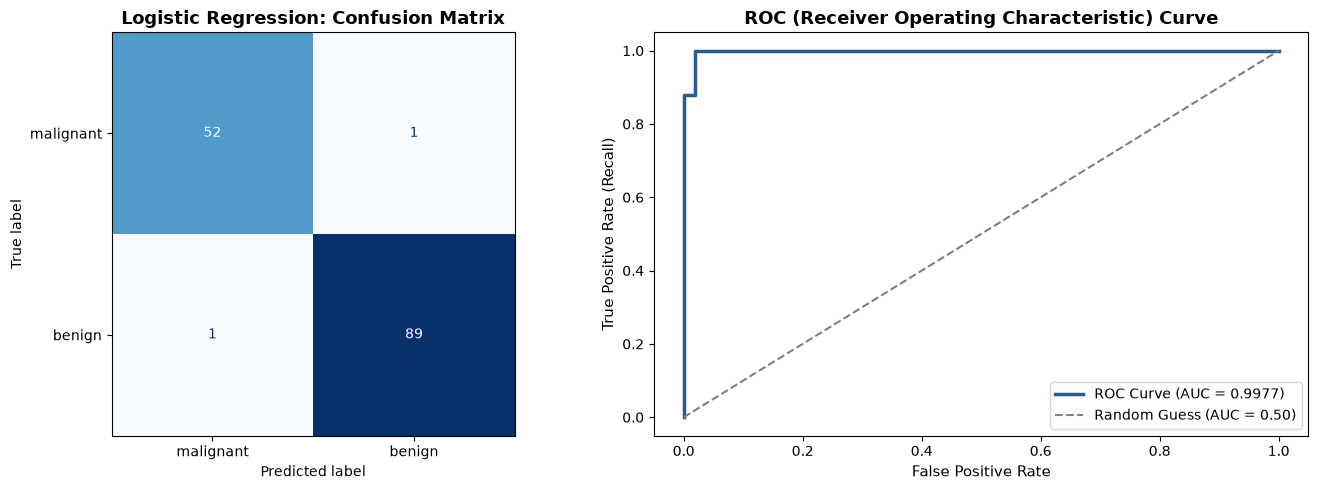

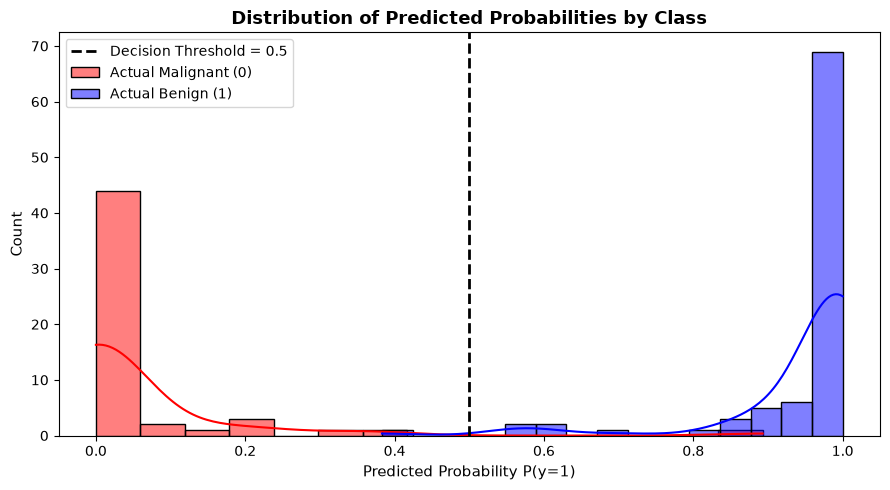

In [32]:
# 8. Visualization: Confusion Matrix, ROC Curve, and Probability Histogram
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Confusion Matrix
disp_c = ConfusionMatrixDisplay(confusion_matrix=cm_c, display_labels=cancer.target_names)
disp_c.plot(cmap="Blues", ax=axes[0], values_format="d", colorbar=False)
axes[0].set_title("Logistic Regression: Confusion Matrix", fontsize=13, fontweight="bold")
axes[0].grid(False)

# Plot 2: ROC Curve
fpr, tpr, _ = roc_curve(y_test_c, y_proba_c)
roc_auc = auc(fpr, tpr)
axes[1].plot(fpr, tpr, color="#2b5c8f", lw=2.5, label=f"ROC Curve (AUC = {roc_auc:.4f})")
axes[1].plot([0, 1], [0, 1], color="grey", lw=1.5, linestyle="--", label="Random Guess (AUC = 0.50)")
axes[1].set_title("ROC (Receiver Operating Characteristic) Curve", fontsize=13, fontweight="bold")
axes[1].set_xlabel("False Positive Rate", fontsize=11)
axes[1].set_ylabel("True Positive Rate (Recall)", fontsize=11)
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

# Plot 3: Probability Distribution by Class
plt.figure(figsize=(9, 5))
sns.histplot(y_proba_c[y_test_c == 0], color="red", label="Actual Malignant (0)", kde=True, bins=15, alpha=0.5)
sns.histplot(y_proba_c[y_test_c == 1], color="blue", label="Actual Benign (1)", kde=True, bins=15, alpha=0.5)
plt.axvline(0.5, color="black", linestyle="--", linewidth=2, label="Decision Threshold = 0.5")
plt.title("Distribution of Predicted Probabilities by Class", fontsize=13, fontweight="bold")
plt.xlabel("Predicted Probability P(y=1)", fontsize=11)
plt.ylabel("Count", fontsize=11)
plt.legend()
plt.tight_layout()
plt.show()


---
# 3. Decision Tree Classifier

Decision Trees recursively partition feature space into pure subsets using split criteria:
- **Gini Impurity:** $\text{Gini}(D) = 1 - \sum_{i=1}^C p_i^2$
- **Entropy (Information Gain):** $\text{Entropy}(D) = -\sum_{i=1}^C p_i \log_2(p_i)$


## 3.1 Decision Tree with Gini Impurity
Multi-class classification on the Iris flower dataset.

> 🍋 **Layman's Analogy ("Explain Like I'm 5"):**
> Think of the game **"20 Questions"**: *"Does it have fur? Yes -> Does it bark? Yes -> It is a dog!"*
> **What is Gini Impurity?** Imagine a bowl of candy. If the bowl only contains green M&Ms, it is 100% pure (Gini = 0). If 10 different colored candies are mixed together, it is total chaos (high Gini). The Decision Tree picks questions that split the data into bowls of pure single colors!


### Step 1: Importing

> 💡 *Beginner Tip:* Think of this step as grabbing your tool kit. We import only the exact tools needed for this recipe so our code stays clean and fast.
Imports for Decision Tree with Gini Impurity.


In [33]:
# 1. Importing libraries for Decision Tree (Gini)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.inspection import DecisionBoundaryDisplay



### Step 2: Loading Dataset

> 💡 *Beginner Tip:* Always look at your data first! Inspecting rows, columns, and feature names ensures there are no surprises or corrupted values.
Loading Iris dataset (150 samples, 4 features, 3 classes: Setosa, Versicolor, Virginica).

[`Iris Dataset`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html)


In [34]:
# 2. Loading Dataset
iris = load_iris(as_frame=True)
df_iris = iris.frame

print(f"Iris Dataset Shape: {df_iris.shape}")
print("Classes:", iris.target_names)
display(df_iris.head(3))


Iris Dataset Shape: (150, 5)
Classes: ['setosa' 'versicolor' 'virginica']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0


### Step 3: Split

> 💡 *Beginner Tip:* Never test a student on the exact same exam questions you used for homework! We lock away 20% of the data to test fairly later.
Partitioning Iris into 70% train and 30% test with stratified sampling.


In [35]:
# 3. Train/Test Split
X_iris = df_iris[iris.feature_names]
y_iris = df_iris['target']

X_train_dt, X_test_dt, y_train_dt, y_test_dt = train_test_split(
    X_iris, y_iris, test_size=0.3, random_state=42, stratify=y_iris
)

print(f"Train samples: {len(X_train_dt)} | Test samples: {len(X_test_dt)}")


Train samples: 105 | Test samples: 45


### Step 4: Train

> 💡 *Beginner Tip:* This is where we choose the model and set its knobs (hyperparameters), like setting an oven to 350°F before putting the food in.
**Key Hyperparameters:**
- `criterion='gini'`: Uses Gini impurity.
- `max_depth=3`: Restricts tree depth to 3 levels to avoid overfitting.


In [36]:
# 4. Train: Model Initialization
dt_gini = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
print("Model initialized:", dt_gini)


Model initialized: DecisionTreeClassifier(max_depth=3, random_state=42)


### Step 5: Fit

> 💡 *Beginner Tip:* This is the actual learning moment! The computer studies the examples and figures out the mathematical patterns.
Fitting decision tree partitions recursively.


In [37]:
# 5. Fit: Model Training
dt_gini.fit(X_train_dt, y_train_dt)
print("Decision Tree fitted successfully!")


Decision Tree fitted successfully!


### Step 6: Predict

> 💡 *Beginner Tip:* Now comes exam time! We feed the test questions to our model and let it make its best guesses.
Generating multi-class predictions on test partition.


In [38]:
# 6. Predict: Model Inference
y_pred_gini = dt_gini.predict(X_test_dt)
print("Predictions:", y_pred_gini)


Predictions: [2 1 2 1 2 2 1 1 0 2 0 0 2 2 0 2 1 0 0 0 1 0 1 2 2 1 1 1 1 0 2 2 1 0 2 0 0
 0 0 2 1 0 2 2 1]


### Step 7: Evaluation

> 💡 *Beginner Tip:* How well did the model do? We compare its guesses with the true answer sheet and calculate report card grades (Accuracy, F1, MSE).
Evaluating multi-class accuracy, classification report, and confusion matrix.


In [39]:
# 7. Evaluation
acc_gini = accuracy_score(y_test_dt, y_pred_gini)
cm_gini = confusion_matrix(y_test_dt, y_pred_gini)

print("=" * 60)
print(f"DECISION TREE (GINI) ACCURACY: {acc_gini:.4f} ({acc_gini*100:.2f}%)")
print("=" * 60)
print(classification_report(y_test_dt, y_pred_gini, target_names=iris.target_names))


DECISION TREE (GINI) ACCURACY: 0.9778 (97.78%)
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       1.00      0.93      0.97        15
   virginica       0.94      1.00      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



### Step 8: Visualization

> 💡 *Beginner Tip:* A picture is worth a thousand numbers! Plots help us and our stakeholders see exactly where the model succeeded and where it struggled.
Visualizing the full Tree Diagram, Feature Importances, Confusion Matrix, and 2D Decision Boundaries.


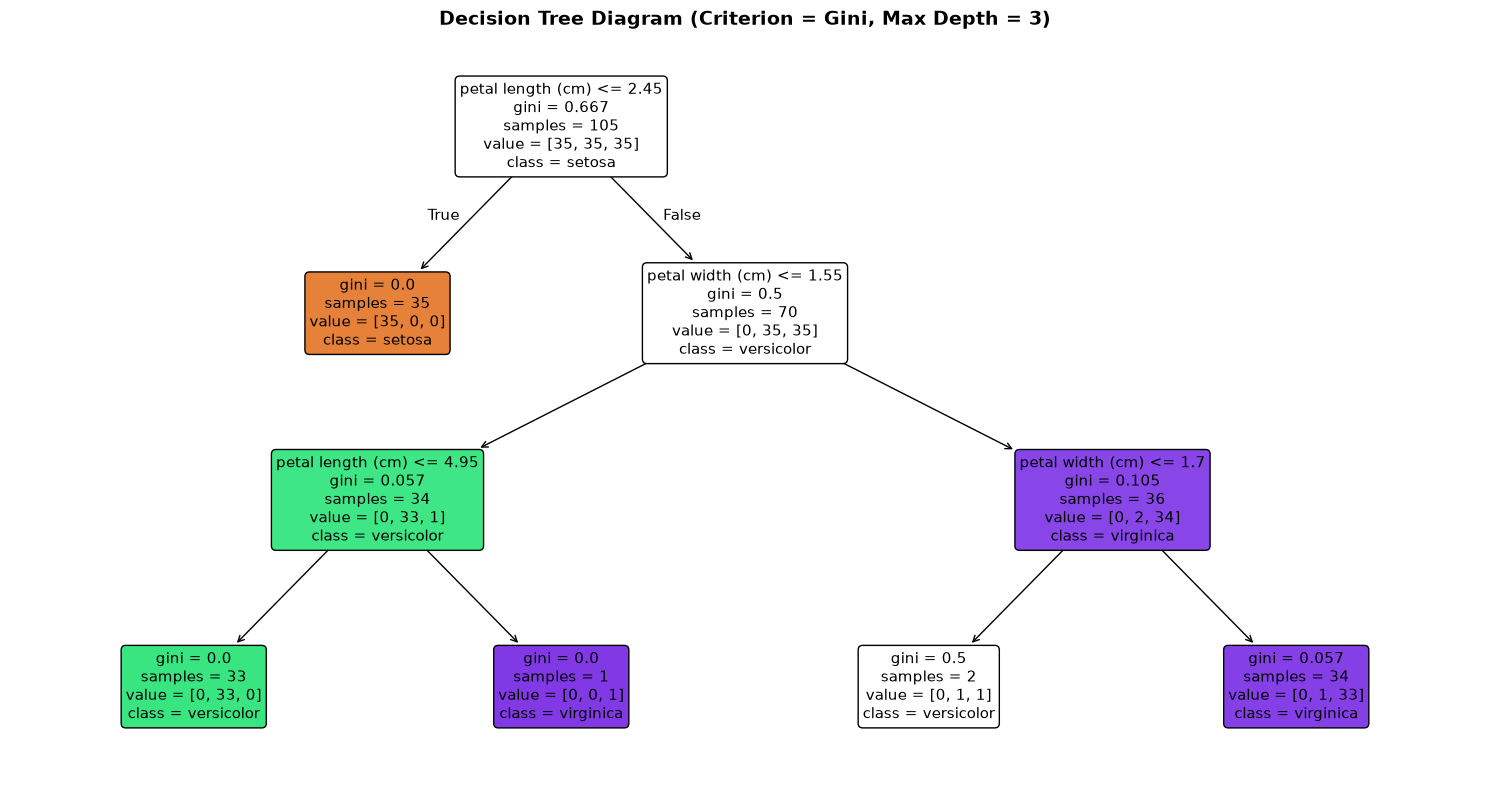

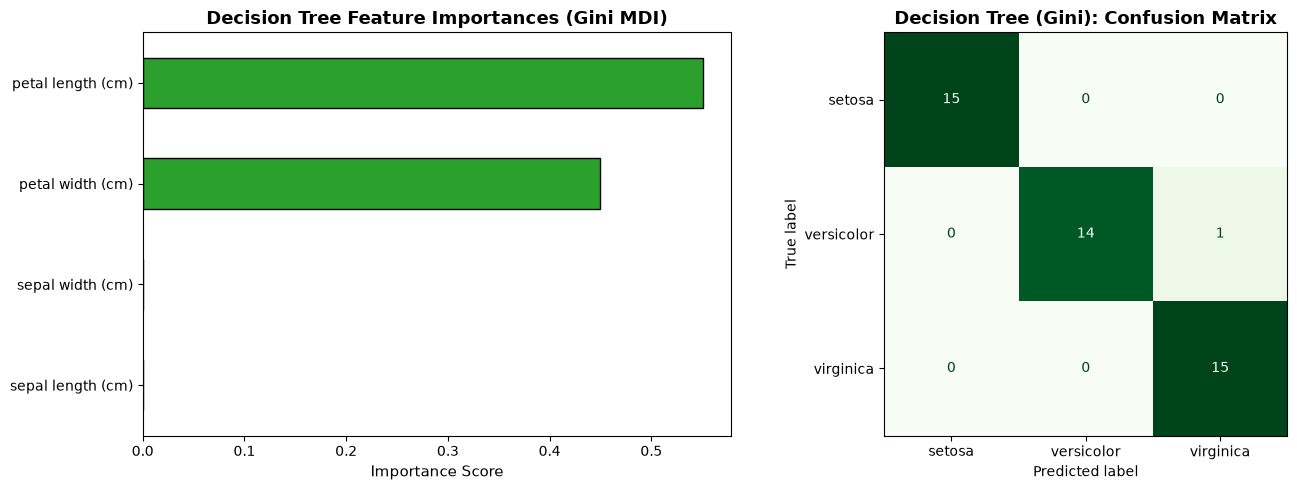

d:\Github\ACC-HPC2026-AIML\.venv\Lib\site-packages\sklearn\inspection\_plot\decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


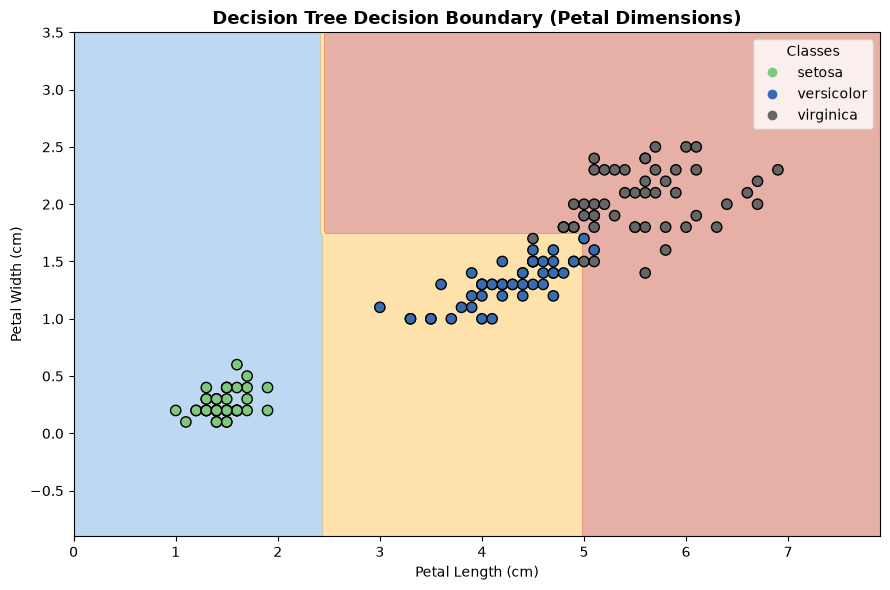

In [40]:
# 8. Visualization: Tree Diagram, Feature Importances & Decision Boundary
# Plot 1: Decision Tree Architecture
plt.figure(figsize=(15, 8))
plot_tree(
    dt_gini,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
    fontsize=11
)
plt.title("Decision Tree Diagram (Criterion = Gini, Max Depth = 3)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# Plot 2: Feature Importances & Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

importances = pd.Series(dt_gini.feature_importances_, index=iris.feature_names).sort_values()
importances.plot(kind="barh", ax=axes[0], color="#2ca02c", edgecolor="black")
axes[0].set_title("Decision Tree Feature Importances (Gini MDI)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Importance Score", fontsize=11)

disp_gini = ConfusionMatrixDisplay(confusion_matrix=cm_gini, display_labels=iris.target_names)
disp_gini.plot(cmap="Greens", ax=axes[1], values_format="d", colorbar=False)
axes[1].set_title("Decision Tree (Gini): Confusion Matrix", fontsize=13, fontweight="bold")
axes[1].grid(False)

plt.tight_layout()
plt.show()

# Plot 3: 2D Decision Boundary on Petal Dimensions
two_feat = ['petal length (cm)', 'petal width (cm)']
X_2d = df_iris[two_feat]
y_2d = df_iris['target']
dt_2d = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_2d, y_2d)

fig, ax = plt.subplots(figsize=(9, 6))
DecisionBoundaryDisplay.from_estimator(
    dt_2d, X_2d, cmap="Accent", alpha=0.35, ax=ax, response_method="predict",
    xlabel="Petal Length (cm)", ylabel="Petal Width (cm)"
)
scatter = ax.scatter(X_2d.iloc[:, 0], X_2d.iloc[:, 1], c=y_2d, cmap="Accent", edgecolors="k", s=55)
ax.set_title("Decision Tree Decision Boundary (Petal Dimensions)", fontsize=13, fontweight="bold")
ax.legend(handles=scatter.legend_elements()[0], labels=list(iris.target_names), title="Classes")
plt.tight_layout()
plt.show()


---
## 3.2 Decision Tree with Entropy (Information Gain)
Training the Decision Tree using Information Gain / Entropy criterion.

> 🍋 **Layman's Analogy ("Explain Like I'm 5"):**
> **Entropy is a measure of surprise!** If you flip a two-headed coin, you have zero surprise (Entropy = 0). If you flip a fair coin, you have maximum uncertainty (Entropy = 1 bit). The tree picks the questions that give the biggest drop in surprise (**Information Gain**), leaving you with the clearest possible answers.


### Step 1: Importing

> 💡 *Beginner Tip:* Think of this step as grabbing your tool kit. We import only the exact tools needed for this recipe so our code stays clean and fast.
Imports for Decision Tree with Entropy.


In [41]:
# 1. Importing libraries for Decision Tree (Entropy)
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay



### Step 2: Loading Dataset

> 💡 *Beginner Tip:* Always look at your data first! Inspecting rows, columns, and feature names ensures there are no surprises or corrupted values.
Using Iris dataset.

[`Iris Dataset`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html)


In [42]:
# 2. Loading Dataset
iris_e = load_iris(as_frame=True)
X_iris_e = iris_e.data
y_iris_e = iris_e.target
display(X_iris_e.head(2))


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2


### Step 3: Split

> 💡 *Beginner Tip:* Never test a student on the exact same exam questions you used for homework! We lock away 20% of the data to test fairly later.
Train/test split (70/30).


In [43]:
# 3. Train/Test Split
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(
    X_iris_e, y_iris_e, test_size=0.3, random_state=42, stratify=y_iris_e
)
print(f"Train samples: {len(X_train_e)} | Test samples: {len(X_test_e)}")


Train samples: 105 | Test samples: 45


### Step 4: Train

> 💡 *Beginner Tip:* This is where we choose the model and set its knobs (hyperparameters), like setting an oven to 350°F before putting the food in.
Initializing Decision Tree with `criterion='entropy'`.


In [44]:
# 4. Train: Model Initialization
dt_entropy = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)
print("Model initialized:", dt_entropy)


Model initialized: DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)


### Step 5: Fit

> 💡 *Beginner Tip:* This is the actual learning moment! The computer studies the examples and figures out the mathematical patterns.
Fitting model on training data.


In [45]:
# 5. Fit: Model Training
dt_entropy.fit(X_train_e, y_train_e)
print("Model fitted with Entropy criterion.")


Model fitted with Entropy criterion.


### Step 6: Predict

> 💡 *Beginner Tip:* Now comes exam time! We feed the test questions to our model and let it make its best guesses.
Generating predictions on test set.


In [46]:
# 6. Predict: Model Inference
y_pred_e = dt_entropy.predict(X_test_e)
print("Predictions:", y_pred_e[:10])


Predictions: [2 1 2 2 2 2 1 1 0 2]


### Step 7: Evaluation

> 💡 *Beginner Tip:* How well did the model do? We compare its guesses with the true answer sheet and calculate report card grades (Accuracy, F1, MSE).
Evaluating performance with Entropy.


In [47]:
# 7. Evaluation
acc_e = accuracy_score(y_test_e, y_pred_e)
cm_e = confusion_matrix(y_test_e, y_pred_e)

print("=" * 60)
print(f"DECISION TREE (ENTROPY) ACCURACY: {acc_e:.4f} ({acc_e*100:.2f}%)")
print("=" * 60)
print(classification_report(y_test_e, y_pred_e, target_names=iris_e.target_names))


DECISION TREE (ENTROPY) ACCURACY: 0.9333 (93.33%)
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       1.00      0.80      0.89        15
   virginica       0.83      1.00      0.91        15

    accuracy                           0.93        45
   macro avg       0.94      0.93      0.93        45
weighted avg       0.94      0.93      0.93        45



### Step 8: Visualization

> 💡 *Beginner Tip:* A picture is worth a thousand numbers! Plots help us and our stakeholders see exactly where the model succeeded and where it struggled.
Plotting the tree structure generated with Entropy.


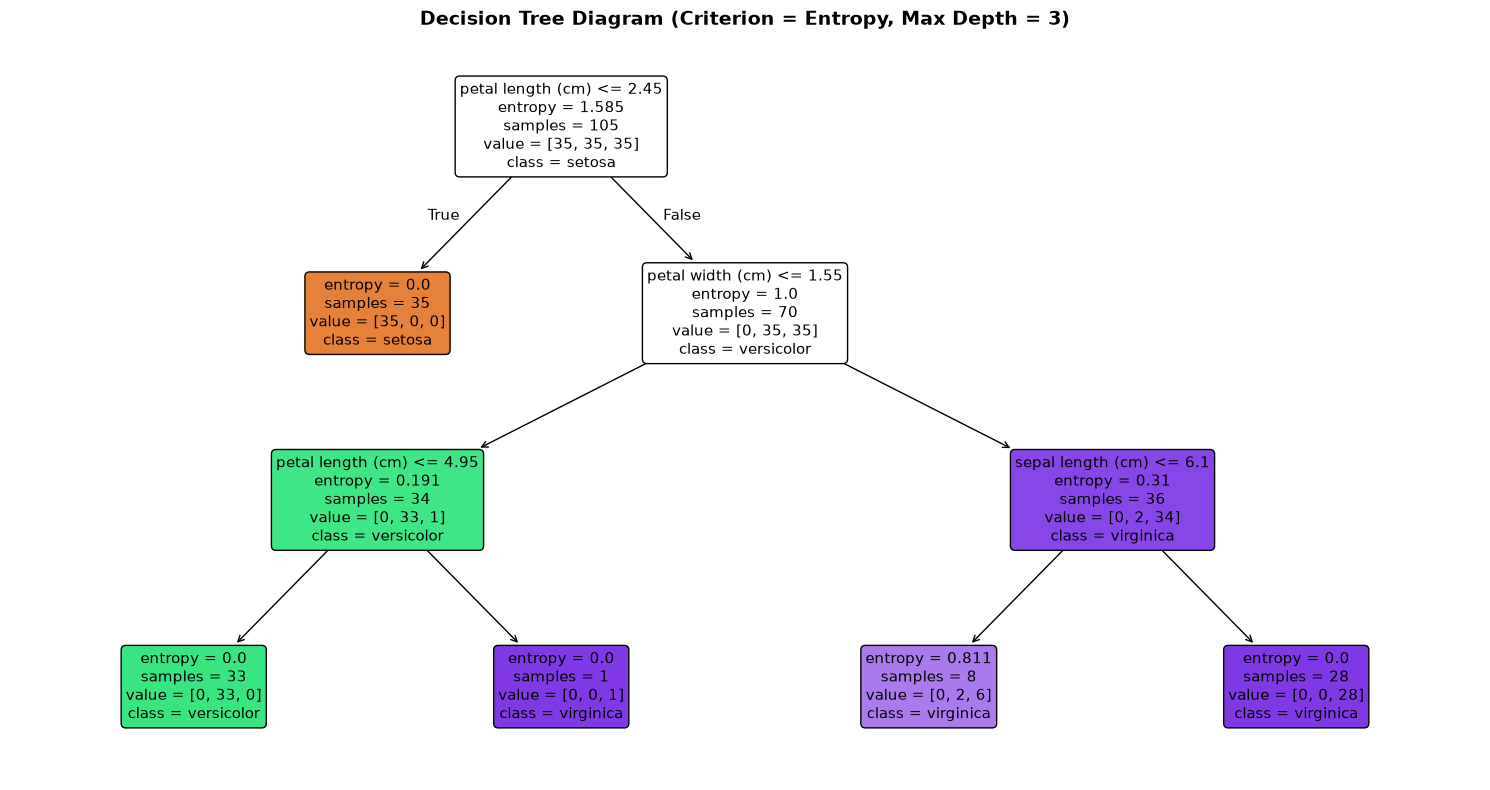

In [48]:
# 8. Visualization: Tree Diagram with Entropy
plt.figure(figsize=(15, 8))
plot_tree(
    dt_entropy,
    feature_names=iris_e.feature_names,
    class_names=iris_e.target_names,
    filled=True,
    rounded=True,
    fontsize=11
)
plt.title("Decision Tree Diagram (Criterion = Entropy, Max Depth = 3)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


---
# 4. Naïve Bayes Classifier

Naïve Bayes is a probabilistic classifier based on **Bayes' Theorem** with the "naïve" assumption of feature conditional independence:
$$P(y|X) = \frac{P(X|y) P(y)}{P(X)} = \frac{P(y) \prod_{j=1}^p P(X_j|y)}{P(X)}$$


## 4.1 Gaussian Naïve Bayes (GaussianNB)
Assumes continuous features within each class follow a normal (Gaussian) distribution:
$$P(X_j|y) = \frac{1}{\sqrt{2\pi\sigma_y^2}} \exp\left(-\frac{(X_j - \mu_y)^2}{2\sigma_y^2}\right)$$

> 🍋 **Layman's Analogy ("Explain Like I'm 5"):**
> Imagine an old-fashioned detective investigating a suspect in the street. The suspect is wearing a raincoat, carrying an umbrella, and splashing through puddles. A "naïve" detective treats each clue **independently** and multiplies their probabilities together. Because all clues point in the same direction, the detective is 99% confident it is raining! Gaussian NB handles continuous numbers like body temperature and height.


### Step 1: Importing

> 💡 *Beginner Tip:* Think of this step as grabbing your tool kit. We import only the exact tools needed for this recipe so our code stays clean and fast.
Imports for Gaussian Naive Bayes.


In [49]:
# 1. Importing libraries for Gaussian Naive Bayes
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.inspection import DecisionBoundaryDisplay



### Step 2: Loading Dataset

> 💡 *Beginner Tip:* Always look at your data first! Inspecting rows, columns, and feature names ensures there are no surprises or corrupted values.
Loading Wine dataset (178 samples, 13 chemical features, 3 cultivars).

[`Wine Dataset`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html)

In [50]:
# 2. Loading Dataset
wine = load_wine(as_frame=True)
df_wine = wine.frame

print(f"Wine Dataset Shape: {df_wine.shape}")
print("Classes:", wine.target_names)
display(df_wine.head(3))


Wine Dataset Shape: (178, 14)
Classes: ['class_0' 'class_1' 'class_2']


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0


### Step 3: Split

> 💡 *Beginner Tip:* Never test a student on the exact same exam questions you used for homework! We lock away 20% of the data to test fairly later.
Train/test split (70% train, 30% test).


In [51]:
# 3. Train/Test Split
X_wine = df_wine[wine.feature_names]
y_wine = df_wine['target']

X_train_nb, X_test_nb, y_train_nb, y_test_nb = train_test_split(
    X_wine, y_wine, test_size=0.3, random_state=42, stratify=y_wine
)

print(f"Train samples: {len(X_train_nb)} | Test samples: {len(X_test_nb)}")


Train samples: 124 | Test samples: 54


### Step 4: Train

> 💡 *Beginner Tip:* This is where we choose the model and set its knobs (hyperparameters), like setting an oven to 350°F before putting the food in.
Initializing Gaussian Naive Bayes model.


In [52]:
# 4. Train: Model Initialization
gnb = GaussianNB()
print("Model initialized:", gnb)


Model initialized: GaussianNB()


### Step 5: Fit

> 💡 *Beginner Tip:* This is the actual learning moment! The computer studies the examples and figures out the mathematical patterns.
Estimating mean $\mu$ and variance $\sigma^2$ per feature per class.


In [53]:
# 5. Fit: Model Training
gnb.fit(X_train_nb, y_train_nb)
print("Learned Class Priors:", gnb.class_prior_.round(3))


Learned Class Priors: [0.331 0.403 0.266]


### Step 6: Predict

> 💡 *Beginner Tip:* Now comes exam time! We feed the test questions to our model and let it make its best guesses.
Generating class predictions and posterior probabilities.


In [54]:
# 6. Predict: Model Inference
y_pred_nb = gnb.predict(X_test_nb)
y_proba_nb = gnb.predict_proba(X_test_nb)
print("First 3 predictions:", y_pred_nb[:3])
print("First 3 probability vectors:")
print(y_proba_nb[:3].round(3))


First 3 predictions: [0 1 0]
First 3 probability vectors:
[[1. 0. 0.]
 [0. 1. 0.]
 [1. 0. 0.]]


### Step 7: Evaluation

> 💡 *Beginner Tip:* How well did the model do? We compare its guesses with the true answer sheet and calculate report card grades (Accuracy, F1, MSE).
Evaluating Gaussian Naive Bayes performance metrics.


In [55]:
# 7. Evaluation
acc_nb = accuracy_score(y_test_nb, y_pred_nb)
cm_nb = confusion_matrix(y_test_nb, y_pred_nb)

print("=" * 60)
print(f"GAUSSIAN NAÏVE BAYES ACCURACY: {acc_nb:.4f} ({acc_nb*100:.2f}%)")
print("=" * 60)
print(classification_report(y_test_nb, y_pred_nb, target_names=wine.target_names))


GAUSSIAN NAÏVE BAYES ACCURACY: 1.0000 (100.00%)
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        18
     class_1       1.00      1.00      1.00        21
     class_2       1.00      1.00      1.00        15

    accuracy                           1.00        54
   macro avg       1.00      1.00      1.00        54
weighted avg       1.00      1.00      1.00        54



### Step 8: Visualization

> 💡 *Beginner Tip:* A picture is worth a thousand numbers! Plots help us and our stakeholders see exactly where the model succeeded and where it struggled.
Visualizing Confusion Matrix, Class Priors, Gaussian Likelihood Density (KDE), and 2D Decision Boundaries.


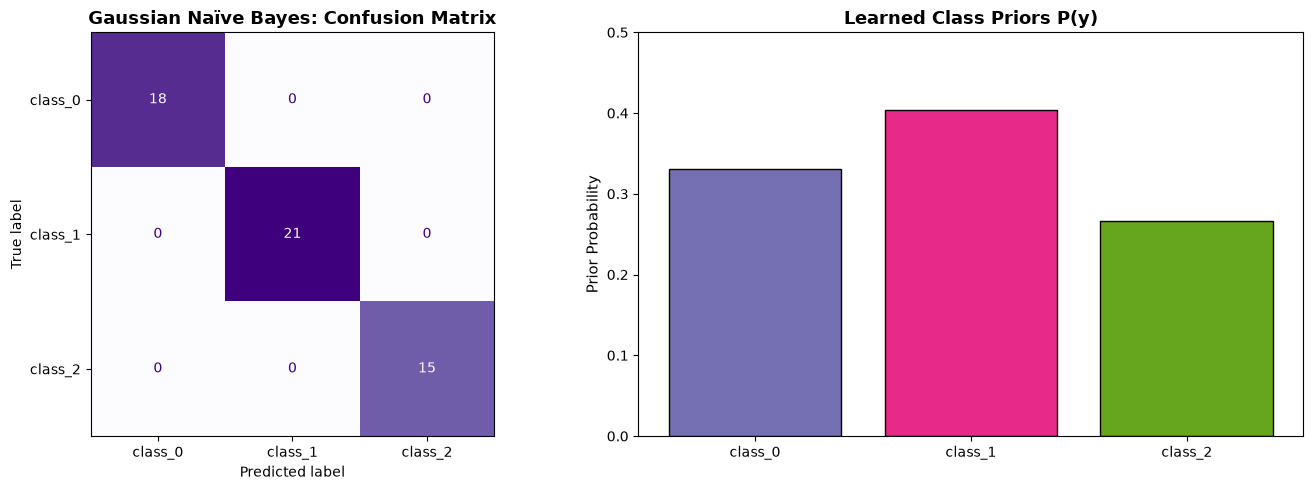

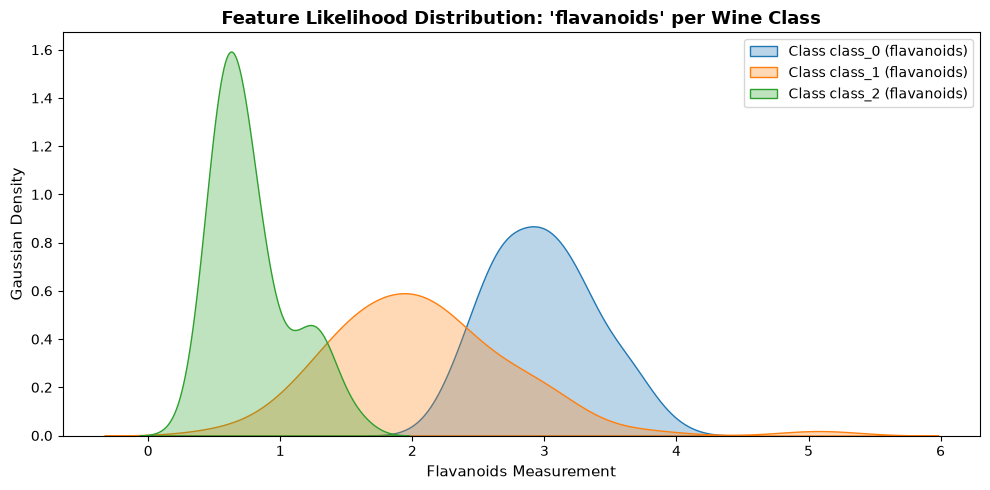

d:\Github\ACC-HPC2026-AIML\.venv\Lib\site-packages\sklearn\inspection\_plot\decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


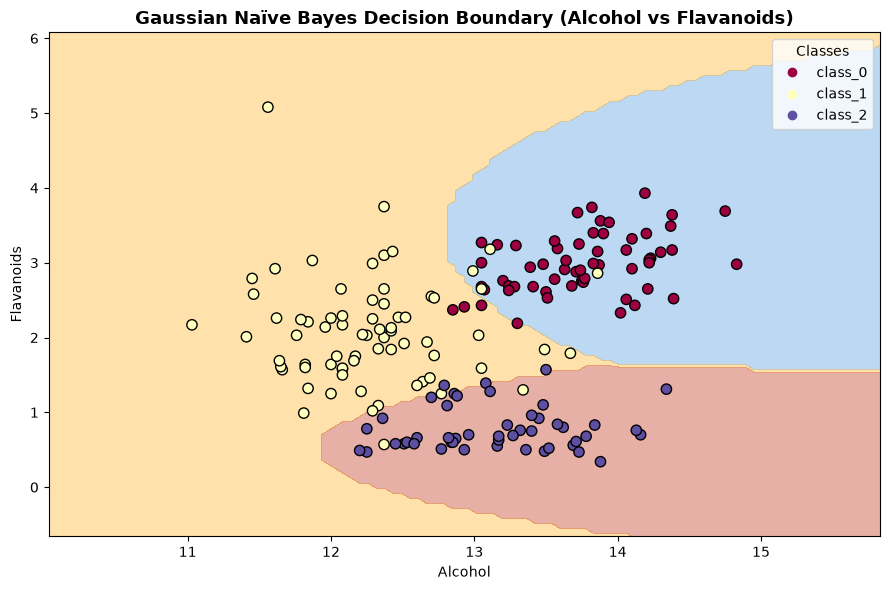

In [56]:
# 8. Visualization: Confusion Matrix, Likelihood Distribution & Decision Boundary
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Confusion Matrix
disp_nb = ConfusionMatrixDisplay(confusion_matrix=cm_nb, display_labels=wine.target_names)
disp_nb.plot(cmap="Purples", ax=axes[0], values_format="d", colorbar=False)
axes[0].set_title("Gaussian Naïve Bayes: Confusion Matrix", fontsize=13, fontweight="bold")
axes[0].grid(False)

# Plot 2: Class Priors
axes[1].bar(wine.target_names, gnb.class_prior_, color=['#7570b3', '#e7298a', '#66a61e'], edgecolor='k')
axes[1].set_title("Learned Class Priors P(y)", fontsize=13, fontweight="bold")
axes[1].set_ylabel("Prior Probability", fontsize=11)
axes[1].set_ylim(0, 0.5)

plt.tight_layout()
plt.show()

# Plot 3: Feature Gaussian Likelihood (KDE)
plt.figure(figsize=(10, 5))
for idx, cname in enumerate(wine.target_names):
    subset = df_wine[df_wine['target'] == idx]['flavanoids']
    sns.kdeplot(subset, label=f"Class {cname} (flavanoids)", fill=True, alpha=0.3)
plt.title("Feature Likelihood Distribution: 'flavanoids' per Wine Class", fontsize=13, fontweight="bold")
plt.xlabel("Flavanoids Measurement", fontsize=11)
plt.ylabel("Gaussian Density", fontsize=11)
plt.legend()
plt.tight_layout()
plt.show()

# Plot 4: 2D Decision Boundary
two_w_feat = ['alcohol', 'flavanoids']
X_w2d = df_wine[two_w_feat]
y_w2d = df_wine['target']
gnb_2d = GaussianNB().fit(X_w2d, y_w2d)

fig, ax = plt.subplots(figsize=(9, 6))
DecisionBoundaryDisplay.from_estimator(
    gnb_2d, X_w2d, cmap="Spectral", alpha=0.35, ax=ax, response_method="predict",
    xlabel="Alcohol", ylabel="Flavanoids"
)
scatter_w = ax.scatter(X_w2d.iloc[:, 0], X_w2d.iloc[:, 1], c=y_w2d, cmap="Spectral", edgecolors="k", s=55)
ax.set_title("Gaussian Naïve Bayes Decision Boundary (Alcohol vs Flavanoids)", fontsize=13, fontweight="bold")
ax.legend(handles=scatter_w.legend_elements()[0], labels=list(wine.target_names), title="Classes")
plt.tight_layout()
plt.show()


---
## 4.2 Multinomial Naïve Bayes (MultinomialNB)
Suited for discrete counts and strictly non-negative features.

> 🍋 **Layman's Analogy ("Explain Like I'm 5"):**
> An email spam filter counting suspicious words! If an incoming email mentions the word "WINNER" 5 times, "FREE" 4 times, and "CASH" 3 times, Multinomial Naïve Bayes tallies up word counts and determines that the probability of spam is overwhelmingly high.


### Step 1: Importing

> 💡 *Beginner Tip:* Think of this step as grabbing your tool kit. We import only the exact tools needed for this recipe so our code stays clean and fast.
Imports for Multinomial Naive Bayes.


In [57]:
# 1. Importing libraries for Multinomial Naive Bayes
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay



### Step 2: Loading Dataset

> 💡 *Beginner Tip:* Always look at your data first! Inspecting rows, columns, and feature names ensures there are no surprises or corrupted values.
Using Wine dataset (all features are strictly non-negative).

[`Wine Dataset`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html)


In [58]:
# 2. Loading Dataset
wine_mnb = load_wine(as_frame=True)
X_mnb = wine_mnb.data
y_mnb = wine_mnb.target
display(X_mnb.head(2))


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0


### Step 3: Split

> 💡 *Beginner Tip:* Never test a student on the exact same exam questions you used for homework! We lock away 20% of the data to test fairly later.
Train/test split (70/30).


In [59]:
# 3. Train/Test Split
X_train_mnb, X_test_mnb, y_train_mnb, y_test_mnb = train_test_split(
    X_mnb, y_mnb, test_size=0.3, random_state=42, stratify=y_mnb
)
print(f"Train samples: {len(X_train_mnb)} | Test samples: {len(X_test_mnb)}")


Train samples: 124 | Test samples: 54


### Step 4: Train

> 💡 *Beginner Tip:* This is where we choose the model and set its knobs (hyperparameters), like setting an oven to 350°F before putting the food in.
Initializing Multinomial Naive Bayes.


In [60]:
# 4. Train: Model Initialization
mnb = MultinomialNB()
print("Model initialized:", mnb)


Model initialized: MultinomialNB()


### Step 5: Fit

> 💡 *Beginner Tip:* This is the actual learning moment! The computer studies the examples and figures out the mathematical patterns.
Fitting multinomial distribution parameters.


In [61]:
# 5. Fit: Model Training
mnb.fit(X_train_mnb, y_train_mnb)
print("Multinomial NB model trained successfully!")


Multinomial NB model trained successfully!


### Step 6: Predict

> 💡 *Beginner Tip:* Now comes exam time! We feed the test questions to our model and let it make its best guesses.
Generating predictions on test set.


In [62]:
# 6. Predict: Model Inference
y_pred_mnb = mnb.predict(X_test_mnb)
print("Predictions:", y_pred_mnb[:10])


Predictions: [0 1 0 0 0 0 2 1 1 1]


### Step 7: Evaluation

> 💡 *Beginner Tip:* How well did the model do? We compare its guesses with the true answer sheet and calculate report card grades (Accuracy, F1, MSE).
Evaluating Multinomial Naive Bayes metrics.


In [63]:
# 7. Evaluation
acc_mnb = accuracy_score(y_test_mnb, y_pred_mnb)
cm_mnb = confusion_matrix(y_test_mnb, y_pred_mnb)

print("=" * 60)
print(f"MULTINOMIAL NAÏVE BAYES ACCURACY: {acc_mnb:.4f} ({acc_mnb*100:.2f}%)")
print("=" * 60)
print(classification_report(y_test_mnb, y_pred_mnb, target_names=wine_mnb.target_names))


MULTINOMIAL NAÏVE BAYES ACCURACY: 0.8889 (88.89%)
              precision    recall  f1-score   support

     class_0       1.00      0.83      0.91        18
     class_1       0.86      0.90      0.88        21
     class_2       0.82      0.93      0.88        15

    accuracy                           0.89        54
   macro avg       0.90      0.89      0.89        54
weighted avg       0.90      0.89      0.89        54



### Step 8: Visualization

> 💡 *Beginner Tip:* A picture is worth a thousand numbers! Plots help us and our stakeholders see exactly where the model succeeded and where it struggled.
Displaying Confusion Matrix heatmap for Multinomial Naive Bayes.


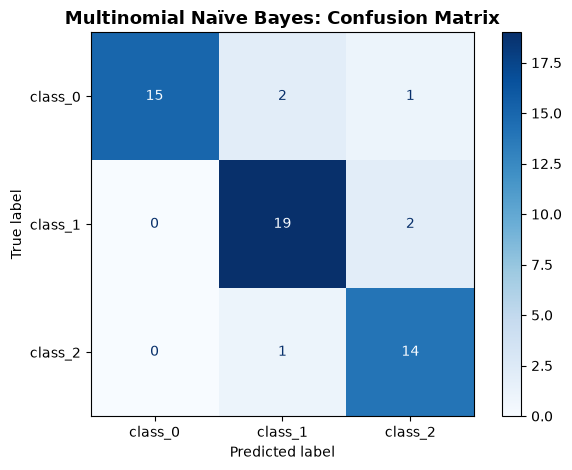

In [64]:
# 8. Visualization: Confusion Matrix
disp_mnb = ConfusionMatrixDisplay(confusion_matrix=cm_mnb, display_labels=wine_mnb.target_names)
disp_mnb.plot(cmap="Blues", values_format="d")
plt.title("Multinomial Naïve Bayes: Confusion Matrix", fontsize=13, fontweight="bold")
plt.grid(False)
plt.tight_layout()
plt.show()


---
## 4.3 Bernoulli Naïve Bayes (BernoulliNB)
Models binary/boolean features by penalizing the non-occurrence of features.

> 🍋 **Layman's Analogy ("Explain Like I'm 5"):**
> Instead of counting how many times a word appears, Bernoulli NB only cares about a simple **Yes/No checklist**: *Did the email contain the word 'lottery'? (Yes/No). Did it have an attachment? (Yes/No).* It looks at presence vs. absence.


### Step 1: Importing

> 💡 *Beginner Tip:* Think of this step as grabbing your tool kit. We import only the exact tools needed for this recipe so our code stays clean and fast.
Imports for Bernoulli Naive Bayes and Binarizer.


In [65]:
# 1. Importing libraries for Bernoulli Naive Bayes
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, Binarizer
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay



### Step 2: Loading Dataset

> 💡 *Beginner Tip:* Always look at your data first! Inspecting rows, columns, and feature names ensures there are no surprises or corrupted values.
Using Wine dataset.

[`Wine Dataset`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html)


In [66]:
# 2. Loading Dataset
wine_bnb = load_wine(as_frame=True)
X_bnb = wine_bnb.data
y_bnb = wine_bnb.target
display(X_bnb.head(2))


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0


### Step 3: Split & Binarization Preprocessing

> 💡 *Beginner Tip:* Never test a student on the exact same exam questions you used for homework! We lock away 20% of the data to test fairly later.
Standardizing continuous features to mean zero and binarizing at threshold 0.0 using `Binarizer(threshold=0.0)`.


In [67]:
# 3. Train/Test Split & Feature Binarization
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_bnb, y_bnb, test_size=0.3, random_state=42, stratify=y_bnb
)

scaler_b = StandardScaler()
X_train_scaled = scaler_b.fit_transform(X_train_b)
X_test_scaled = scaler_b.transform(X_test_b)

binarizer = Binarizer(threshold=0.0)
X_train_bin = binarizer.fit_transform(X_train_scaled)
X_test_bin = binarizer.transform(X_test_scaled)

print(f"Binarized sample shape: {X_train_bin.shape} (binary values 0 or 1)")


Binarized sample shape: (124, 13) (binary values 0 or 1)


### Step 4: Train

> 💡 *Beginner Tip:* This is where we choose the model and set its knobs (hyperparameters), like setting an oven to 350°F before putting the food in.
Initializing Bernoulli Naive Bayes model.


In [68]:
# 4. Train: Model Initialization
bnb = BernoulliNB()
print("Model initialized:", bnb)


Model initialized: BernoulliNB()


### Step 5: Fit

> 💡 *Beginner Tip:* This is the actual learning moment! The computer studies the examples and figures out the mathematical patterns.
Fitting Bernoulli parameters.


In [69]:
# 5. Fit: Model Training
bnb.fit(X_train_bin, y_train_b)
print("Bernoulli NB trained successfully!")


Bernoulli NB trained successfully!


### Step 6: Predict

> 💡 *Beginner Tip:* Now comes exam time! We feed the test questions to our model and let it make its best guesses.
Generating predictions on binarized test set.


In [70]:
# 6. Predict: Model Inference
y_pred_bnb = bnb.predict(X_test_bin)
print("Predictions:", y_pred_bnb[:10])


Predictions: [0 1 0 0 0 0 2 1 1 1]


### Step 7: Evaluation

> 💡 *Beginner Tip:* How well did the model do? We compare its guesses with the true answer sheet and calculate report card grades (Accuracy, F1, MSE).
Evaluating Bernoulli Naive Bayes metrics.


In [71]:
# 7. Evaluation
acc_bnb = accuracy_score(y_test_b, y_pred_bnb)
cm_bnb = confusion_matrix(y_test_b, y_pred_bnb)

print("=" * 60)
print(f"BERNOULLI NAÏVE BAYES ACCURACY: {acc_bnb:.4f} ({acc_bnb*100:.2f}%)")
print("=" * 60)
print(classification_report(y_test_b, y_pred_bnb, target_names=wine_bnb.target_names))


BERNOULLI NAÏVE BAYES ACCURACY: 0.9074 (90.74%)
              precision    recall  f1-score   support

     class_0       0.94      0.94      0.94        18
     class_1       0.90      0.86      0.88        21
     class_2       0.88      0.93      0.90        15

    accuracy                           0.91        54
   macro avg       0.91      0.91      0.91        54
weighted avg       0.91      0.91      0.91        54



### Step 8: Visualization

> 💡 *Beginner Tip:* A picture is worth a thousand numbers! Plots help us and our stakeholders see exactly where the model succeeded and where it struggled.
Displaying Confusion Matrix heatmap for Bernoulli Naive Bayes.


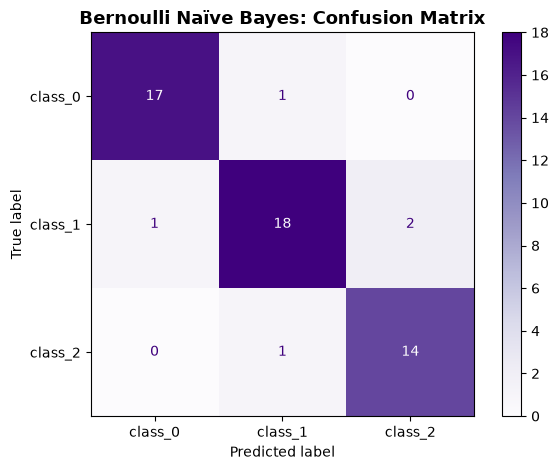

In [72]:
# 8. Visualization: Confusion Matrix
disp_bnb = ConfusionMatrixDisplay(confusion_matrix=cm_bnb, display_labels=wine_bnb.target_names)
disp_bnb.plot(cmap="Purples", values_format="d")
plt.title("Bernoulli Naïve Bayes: Confusion Matrix", fontsize=13, fontweight="bold")
plt.grid(False)
plt.tight_layout()
plt.show()


---
## 5. Comparative Summary: Supervised Learning Guide

| Model | Task Type | Key Strengths | Key Limitations | Scaling Required? | Key Evaluation Metrics |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Linear Regression** | Regression | Simple, highly interpretable, fast closed-form solution | Assumes linearity, sensitive to outliers | Recommended for regularized/gradient models | $R^2$, MSE, RMSE, MAE |
| **Polynomial Regression** | Regression | Models non-linear curves while remaining linear in parameters | Prone to overfitting at high degrees | Recommended | $R^2$, MSE, RMSE, MAE |
| **Logistic Regression** | Binary / Multi-class Classification | Well-calibrated probabilities, efficient, interpretable | Assumes linear boundary in log-odds | **Yes** (Sensitive to magnitude) | Accuracy, Confusion Matrix, Classification Report, ROC-AUC |
| **Decision Tree** | Classification & Regression | Non-linear, white-box interpretability, handles mixed types | Prone to overfitting without depth limits | **No** (Invariant to monotonic transforms) | Accuracy, Classification Report, Confusion Matrix, Gini / Entropy |
| **Gaussian Naïve Bayes** | Classification | Extremely fast, excels with high dimensions / small datasets | Assumes feature independence | **No** (Learns separate mean & variance) | Accuracy, Classification Report, Confusion Matrix |
| **Multinomial Naïve Bayes** | Classification | Ideal for discrete counts and text data | Requires non-negative counts | **No** | Accuracy, Classification Report, Confusion Matrix |
| **Bernoulli Naïve Bayes** | Classification | Ideal for binary occurrence data, penalizes absent features | Requires binary features | **No** | Accuracy, Classification Report, Confusion Matrix |
